In [1]:
%%capture captured_output
%%time
%pip install numpy==1.26 matplotlib==3.9.2 tensorflow==2.19
%pip install torch==2.8.0+cpu torchvision==0.23.0+cpu torchaudio==2.8.0+cpu \
--index-url https://download.pytorch.org/whl/cpu

In [3]:
output_txt=captured_output.stdout
output_split = output_txt.splitlines()

varify = ['error' if any('error' in x for x in output_split) else 'sucess']
print(varify)

['sucess']


In [4]:
import skillsnetwork
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np


2026-10-28 13:24:18.759082: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-28 13:24:18.761117: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-28 13:24:18.858729: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-28 13:24:18.894072: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793208258.951267   13374 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793208258.96

In [5]:
url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/4Z1fwRR295-1O3PMQBH6Dg/images-dataSAT.tar"
await skillsnetwork.prepare(url=url, path='./', overwrite=True)


  0%|          | 0/6003 [00:00<?, ?it/s]

Saved to '.'


In [15]:
base_dir = './images_dataSAT/'
none_agri = os.path.join(base_dir, 'class_0_non_agri')
agri = os.path.join(base_dir, 'class_1_agri')

In [34]:

x = [os.path.join(none_agri, i) for i in os.listdir(none_agri)] + [os.path.join(agri, i) for i in os.listdir(agri)]

y = [0] * len(os.listdir(none_agri)) + [1] * len(os.listdir(agri))



In [41]:
def manual_process(image_paths, labels, batch_size, target_size):
    sample_size = len(image_paths)

    while True:
        indices = np.arange(sample_size)
        np.random.shuffle(indices)

        shuffle_image = np.array(image_paths)[indices]
        shuffle_label = np.array(labels)[indices]

        for i in range(0, sample_size, batch_size):
            batch_path = shuffle_image[i: i +batch_size]
            batch_label = shuffle_label[i: i+batch_size]

            batch_list = []
            for b in batch_path:
                b_path = tf.keras.utils.load_img(b)
                b_label = tf.keras.utils.img_to_array(b_path)
                batch_list.append(b_label)

            yield np.array(batch_list) / 255.0, np.array(b_label)

my_generator = manual_process(image_paths=x, labels=y, batch_size=8, target_size=(64,64))

image, label =next(my_generator)


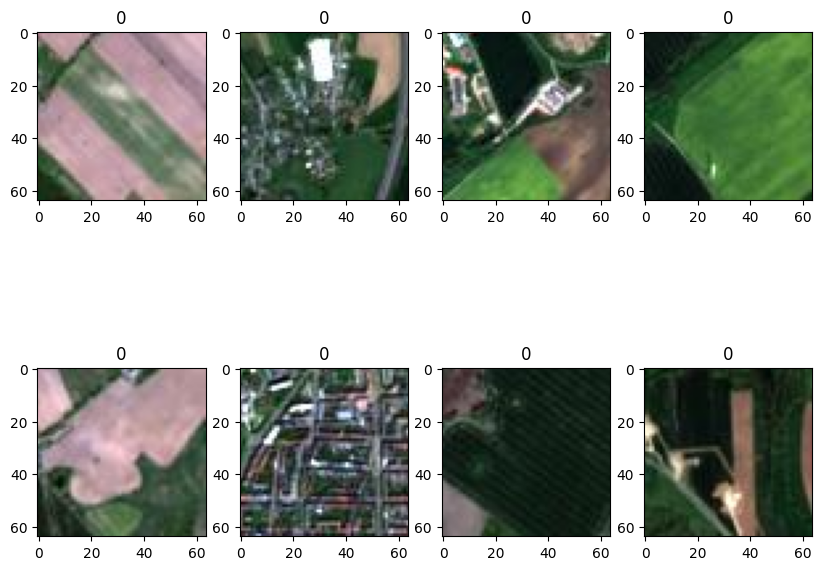

In [115]:
plt.figure(figsize=(10,8))
for n, (img, pos) in enumerate(zip(image, label), start=1):
    plt.subplot(2,4, n)
    plt.imshow(img)
    plt.title(y[n])
plt.show()

